<a href="https://colab.research.google.com/github/momensaleh193-png/Machine-learning-course/blob/main/Week5_Part2_Visualization_Multicollinearity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 5 Part 2: Data Visualization & Multicollinearity

**Instructor:** Dr. Mahmoud Eid (m.eid@fci-cu.edu.eg)
**Time:** ~1.5 hours

<div dir="rtl">
<b>النهاردة هنتعلم ازاي نستكشف الـ data ونكتشف المشاكل قبل الـ training بإذن الله!</b>
</div>

## Topics

1. Data Visualization Fundamentals
2. Correlation Analysis
3. Multicollinearity Detection (VIF)
4. Handling Multicollinearity: pairwise vs. VIF-based removal

**Real Dataset:** California Housing (20,640 houses)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import train_test_split

plt.style.use('dark_background')
np.random.seed(42)
print("✅ Ready!")

✅ Ready!


---

# 1. Data Visualization Fundamentals

**Why Visualize?**

- Understand data distribution
- Detect outliers
- Identify relationships between features
- Make informed preprocessing decisions


In [2]:
# Load California Housing dataset
housing = fetch_california_housing()
df_housing = pd.DataFrame(housing.data, columns=housing.feature_names)
df_housing['Price'] = housing.target

print(f"Dataset: California Housing")
print(f"Samples: {len(df_housing)}")
print(f"Features: {housing.feature_names}")
print(f"\nPreview:")
print(df_housing.head())

Dataset: California Housing
Samples: 20640
Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Preview:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  Price  
0    -122.23  4.526  
1    -122.22  3.585  
2    -122.24  3.521  
3    -122.25  3.413  
4    -122.25  3.422  


In [3]:
# Statistical summary
print("Statistical Summary:")
print(df_housing.describe())

Statistical Summary:
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.499900      1.000000      0.846154      0.333333      3.000000   
25%        2.563400     18.000000      4.440716      1.006079    787.000000   
50%        3.534800     29.000000      5.229129      1.048780   1166.000000   
75%        4.743250     37.000000      6.052381      1.099526   1725.000000   
max       15.000100     52.000000    141.909091     34.066667  35682.000000   

           AveOccup      Latitude     Longitude         Price  
count  20640.000000  20640.000000  20640.000000  20640.000000  
mean       3.070655     35.631861   -119.569704      2.068558  
std       10.386050      2.135952      2.003532      1.153956  
min        

### Distribution Analysis


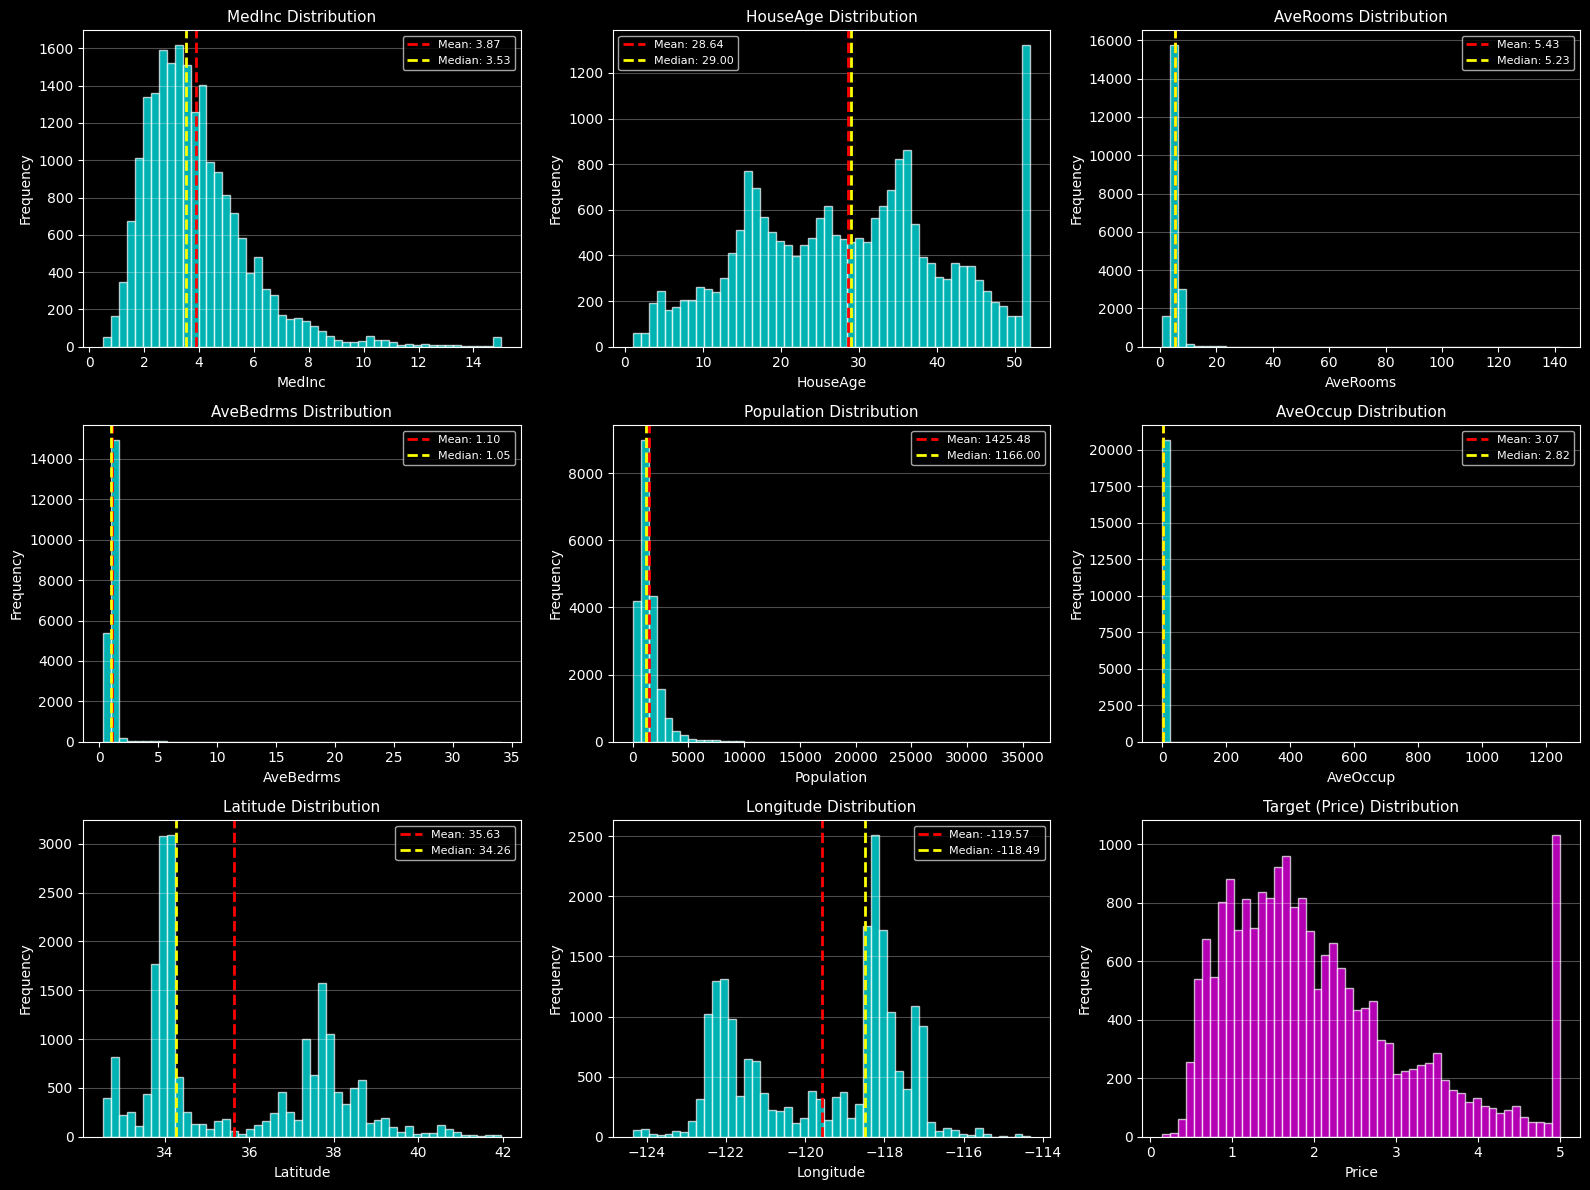

In [4]:
# Feature distributions
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(housing.feature_names):
    axes[i].hist(df_housing[col], bins=50, alpha=0.7, color='cyan', edgecolor='white')
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel('Frequency', fontsize=10)
    axes[i].set_title(f'{col} Distribution', fontsize=11)
    axes[i].grid(alpha=0.3, axis='y')

    # Add mean and median lines
    mean_val = df_housing[col].mean()
    median_val = df_housing[col].median()
    axes[i].axvline(mean_val, color='red', linestyle='--', linewidth=2,
                    label=f'Mean: {mean_val:.2f}')
    axes[i].axvline(median_val, color='yellow', linestyle='--', linewidth=2,
                    label=f'Median: {median_val:.2f}')
    axes[i].legend(fontsize=8)

# Target distribution
axes[8].hist(df_housing['Price'], bins=50, alpha=0.7, color='magenta', edgecolor='white')
axes[8].set_xlabel('Price', fontsize=10)
axes[8].set_ylabel('Frequency', fontsize=10)
axes[8].set_title('Target (Price) Distribution', fontsize=11)
axes[8].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

### Box Plots for Outlier Detection

Box plots show:

- **Box:** 25th to 75th percentile (IQR)
- **Line:** Median
- **Whiskers:** 1.5 × IQR
- **Points:** Outliers


/tmp/ipykernel_5363/2012580501.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[i].boxplot([df_housing[col]], labels=[col], patch_artist=True)
/tmp/ipykernel_5363/2012580501.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[i].boxplot([df_housing[col]], labels=[col], patch_artist=True)
/tmp/ipykernel_5363/2012580501.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[i].boxplot([df_housing[col]], labels=[col], patch_artist=True)
/tmp/ipykernel_5363/2012580501.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; s

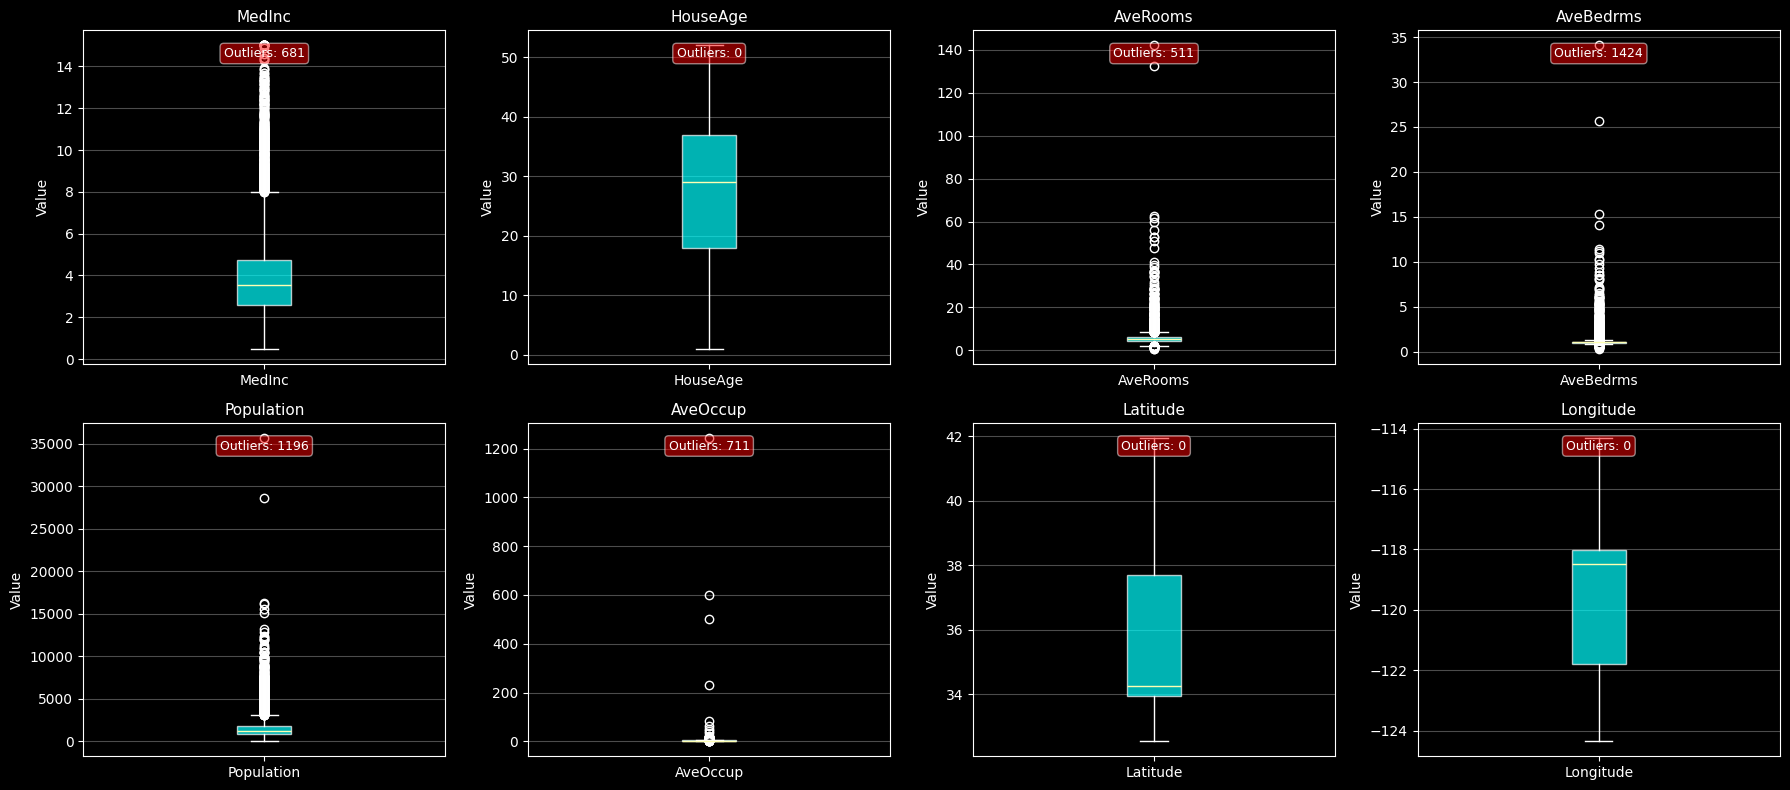

In [5]:
# Box plots for outlier detection
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(housing.feature_names):
    bp = axes[i].boxplot([df_housing[col]], labels=[col], patch_artist=True)
    for patch in bp['boxes']:
        patch.set_facecolor('cyan')
        patch.set_alpha(0.7)
    axes[i].set_ylabel('Value', fontsize=10)
    axes[i].set_title(f'{col}', fontsize=11)
    axes[i].grid(alpha=0.3, axis='y')

    # Count outliers
    Q1 = df_housing[col].quantile(0.25)
    Q3 = df_housing[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = ((df_housing[col] < Q1 - 1.5*IQR) | (df_housing[col] > Q3 + 1.5*IQR)).sum()
    axes[i].text(0.5, 0.95, f'Outliers: {outliers}',
                 transform=axes[i].transAxes, ha='center', va='top',
                 bbox=dict(boxstyle='round', facecolor='red', alpha=0.5), fontsize=9)

plt.tight_layout()
plt.show()

### Scatter Plot Matrix (Pair Plot)

Shows relationships between all feature pairs.


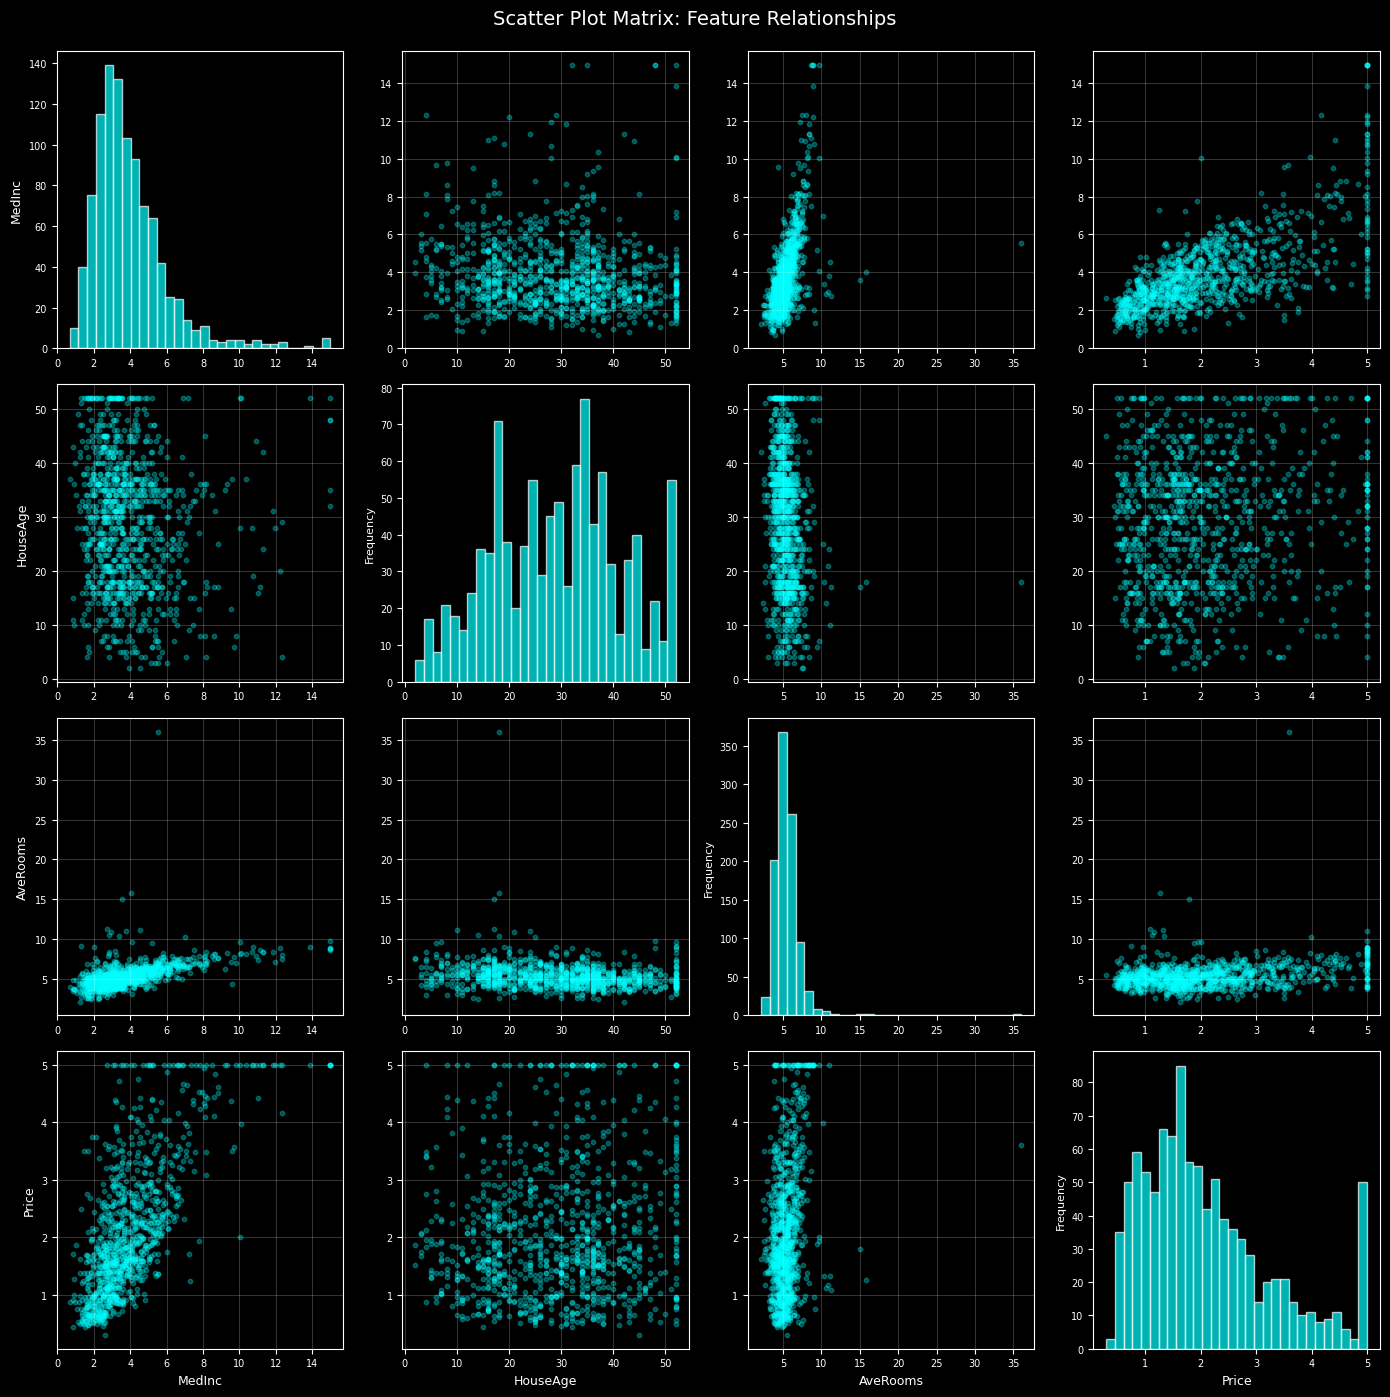

In [6]:
# Scatter plot matrix (subset of features for clarity)
features_subset = ['MedInc', 'HouseAge', 'AveRooms', 'Price']
df_subset = df_housing[features_subset].sample(1000, random_state=42)

fig = plt.figure(figsize=(14, 14))
n_features = len(features_subset)

for i in range(n_features):
    for j in range(n_features):
        ax = plt.subplot(n_features, n_features, i * n_features + j + 1)

        if i == j:
            # Diagonal: notice that correlation would be highest because this is the feature with itself so instead we put histograms here
            # see how this figure captures many things at once
            ax.hist(df_subset.iloc[:, i], bins=30, color='cyan', alpha=0.7, edgecolor='white')
            ax.set_ylabel('Frequency', fontsize=8)
        else:
            # Off-diagonal: scatter plots
            ax.scatter(df_subset.iloc[:, j], df_subset.iloc[:, i],
                       alpha=0.3, s=10, color='cyan')
            ax.grid(alpha=0.2)

        # Labels
        if i == n_features - 1:
            ax.set_xlabel(features_subset[j], fontsize=9)
        if j == 0:
            ax.set_ylabel(features_subset[i], fontsize=9)

        ax.tick_params(labelsize=7)

plt.suptitle('Scatter Plot Matrix: Feature Relationships', fontsize=14, y=0.995)
plt.tight_layout()
plt.show()

### Exercise 1: Create Box Plots

**Task:** Create box plots for the Diabetes dataset to identify outliers.


In [7]:
# Load diabetes dataset
from sklearn.datasets import load_diabetes
diabetes = load_diabetes()
df_diabetes = pd.DataFrame(diabetes.data[:, :5],
                           columns=['Age', 'Sex', 'BMI', 'BP', 'S1'])

print(f"Diabetes dataset: {df_diabetes.shape}")
print(df_diabetes.head())

Diabetes dataset: (442, 5)
        Age       Sex       BMI        BP        S1
0  0.038076  0.050680  0.061696  0.021872 -0.044223
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449
2  0.085299  0.050680  0.044451 -0.005670 -0.045599
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191
4  0.005383 -0.044642 -0.036385  0.021872  0.003935


/tmp/ipykernel_5363/425415299.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[i].boxplot([df_diabetes[col]] , labels=[col] , patch_artist=True)
/tmp/ipykernel_5363/425415299.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[i].boxplot([df_diabetes[col]] , labels=[col] , patch_artist=True)
/tmp/ipykernel_5363/425415299.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[i].boxplot([df_diabetes[col]] , labels=[col] , patch_artist=True)
/tmp/ipykernel_5363/425415299.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3

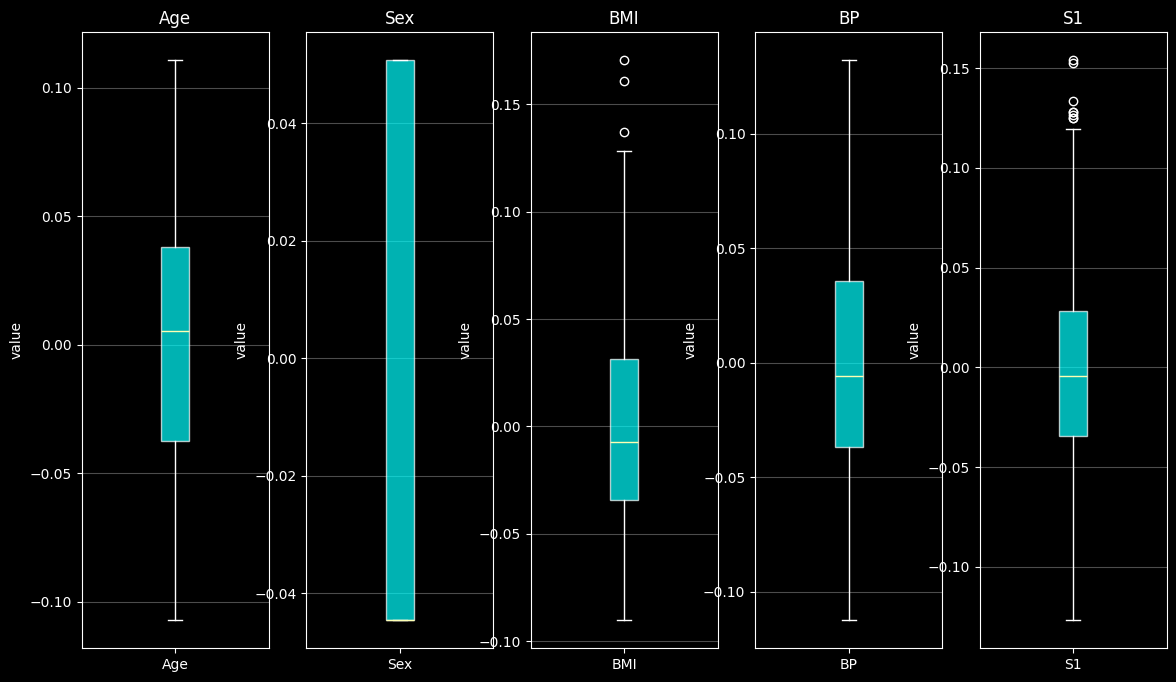

In [10]:
# YOUR TASK: Create box plots for all 5 features
# YOUR CODE HERE

figure , axes = plt.subplots(1,5,figsize=(14,8))
axes = axes.flatten()

for i , col in enumerate(df_diabetes.columns):
    bp = axes[i].boxplot([df_diabetes[col]] , labels=[col] , patch_artist=True)
    for patch in bp["boxes"] :
       patch.set_facecolor("cyan")
       patch.set_alpha(.7)


    axes[i].set_title(f"{col}")
    axes[i].set_ylabel("value")
    axes[i].grid(alpha=.3 , axis="y")

In [11]:
# print("✅ Exercise 1 passed!")

---

# 2. Correlation Analysis

**Correlation coefficient (r):**

- **r = 1:** Perfect positive correlation
- **r = 0:** No correlation
- **r = -1:** Perfect negative correlation

$$r = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2 \sum (y_i - \bar{y})^2}}$$


In [12]:
# Compute correlation matrix
corr_matrix = df_housing.corr()

print("Correlation with Target (Price):")
print(corr_matrix['Price'].sort_values(ascending=False))

Correlation with Target (Price):
Price         1.000000
MedInc        0.688075
AveRooms      0.151948
HouseAge      0.105623
AveOccup     -0.023737
Population   -0.024650
Longitude    -0.045967
AveBedrms    -0.046701
Latitude     -0.144160
Name: Price, dtype: float64


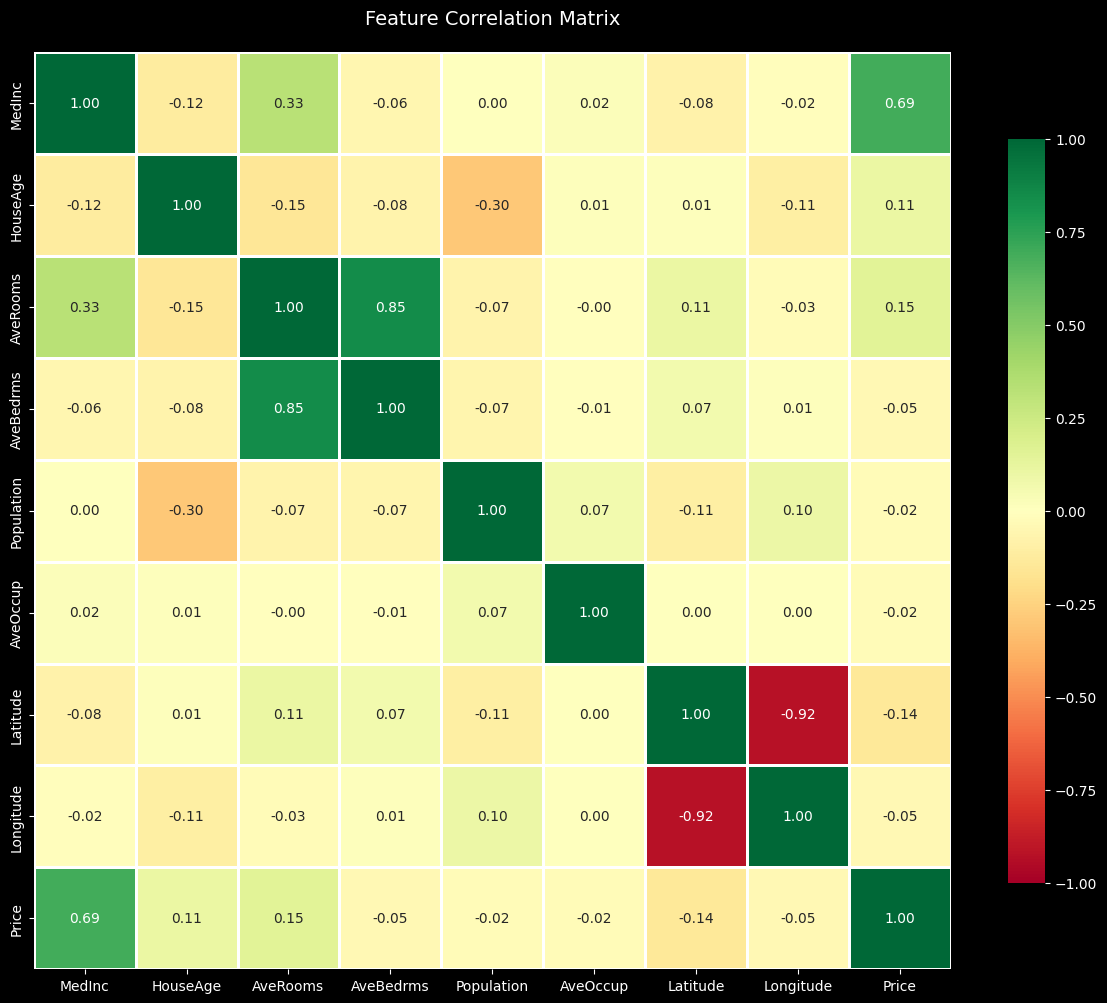

In [13]:
# Correlation heatmap .. note how the color reflects the value (use the colorbar on the right as the reference)
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdYlGn', center=0,
            square=True, linewidths=1, cbar_kws={"shrink": 0.8},
            vmin=-1, vmax=1, ax=ax)
ax.set_title('Feature Correlation Matrix', fontsize=14, pad=20)
plt.tight_layout()
plt.show()

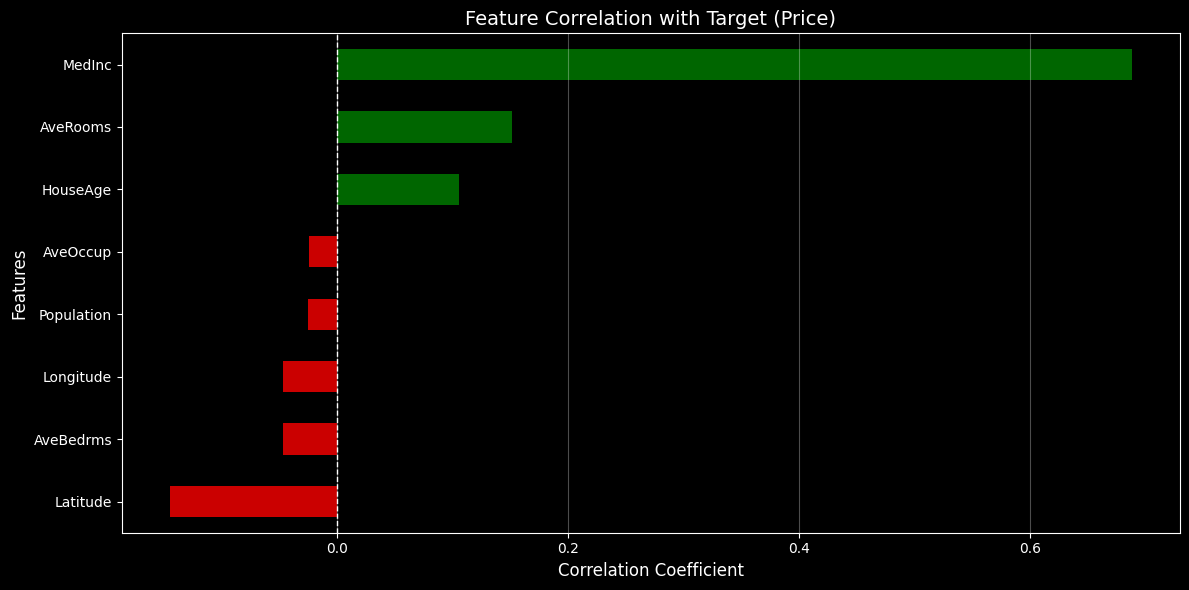

In [14]:
# Target correlation bar plot, see how we can use this plot to visualise correlation values
fig, ax = plt.subplots(figsize=(12, 6))
target_corr = corr_matrix['Price'].drop('Price').sort_values()
colors = ['red' if x < 0 else 'green' for x in target_corr]  # to change that to specific color based on direction of correlation
target_corr.plot(kind='barh', color=colors, ax=ax, alpha=0.8)
ax.set_xlabel('Correlation Coefficient', fontsize=12)
ax.set_ylabel('Features', fontsize=12)
ax.set_title('Feature Correlation with Target (Price)', fontsize=14)
ax.axvline(0, color='white', linestyle='--', linewidth=1)
ax.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

### Exercise 2: Find Highly Correlated Features

**Task:** Identify all feature pairs with |correlation| > 0.7


In [28]:
# YOUR TASK: Find highly correlated pairs
# YOUR CODE HERE
corr = df_housing.corr()
high_corr_pairs = []
cols = corr.columns
for i in range(len(cols)) :
   for j in range(i+1 , len(cols)) :
       if abs(corr.iloc[i,j]) >.7 :
           high_corr_pairs.append((cols[i] , cols[j] , corr.iloc[i,j]))


print(f"\nFound {len(high_corr_pairs)} highly correlated pairs")


Found 2 highly correlated pairs


In [29]:
# print("✅ Exercise 2 passed!")

---

# 3. Multicollinearity Detection

**Multicollinearity:** When features are highly correlated with each other

**Problems it causes:**

1. Unstable coefficient estimates
2. High variance in predictions
3. Difficulty interpreting feature importance

**Detection Methods: we can visually inspect correlations to detect it and we can also use Variance Inflation Factor (VIF)**

VIF is built on **R²** (the coefficient of determination), so we start by understanding R² with a tiny example, then build VIF on top of it.

### 3.1 Background: what is R² (coefficient of determination)?

**Why variation?** A feature's information lies in its **variability**. If every observation had the same value (the mean), 1,000 observations would tell us no more than one: the mean is a baseline anyone can predict for free. So $R^2$ asks: how much of a feature's variation (its deviations from the mean) can the other features reproduce? If all of it, the feature adds nothing new.

$R^2$ answers: **"what fraction of a variable's variation can be explained by other variables?"**

$R^2$ is **not** the correlation coefficient $r$ from Section 2. With only **one** predictor $R^2 = r^2$, but with several predictors $R^2$ measures how well they explain the variable **together**. It can be high even when no single pair looks strongly correlated (e.g. $X_3 \approx X_1 + X_2$).

**Toy example:** can the number of **rooms** ($X_2$) predict the house **size** ($X_1$)?

| House | Rooms ($X_2$) | Size ($X_1$, m²) |
|---|---|---|
| A | 1 | 50 |
| B | 2 | 110 |
| C | 3 | 120 |
| D | 4 | 130 |
| E | 5 | 190 |

**Step 1: $SS_{tot}$, the mistake when we know nothing.** The best guess is the mean (120 m²) for every house:

$$SS_{tot} = \sum_n (x_n - \bar{x})^2 = 70^2 + 10^2 + 0^2 + 10^2 + 70^2 = 10000$$

**Step 2: $SS_{res}$, the mistake left after using the other feature.** Fit a line: $\widehat{\text{size}} = 30 + 30 \times \text{rooms}$, which predicts 60, 90, 120, 150, 180:

$$SS_{res} = \sum_n (x_n - \hat{x}_n)^2 = 10^2 + 20^2 + 0^2 + 20^2 + 10^2 = 1000$$

**Step 3: $R^2$, the share of the mistake that went away.**

$$R^2 = 1 - \frac{SS_{res}}{SS_{tot}} = 1 - \frac{1000}{10000} = 0.90$$

→ Rooms explain **90%** of the variation in size; only **10%** of the size information is unique.

Run the next cell to see this.

Fitted line: size = 30 + 30 × rooms

House  Rooms  Size  Mean  Err_mean²  Pred  Err_line²
  A     1      50  120      4900     60      100
  B     2     110  120       100     90      400
  C     3     120  120         0    120        0
  D     4     130  120       100    150      400
  E     5     190  120      4900    180      100

SS_tot = 10000    SS_res = 1000
R² = 1 - 1000/10000 = 0.90
Check with sklearn: 0.90
Correlation r = 0.9487  →  r² = 0.90  (same as R² with ONE predictor)


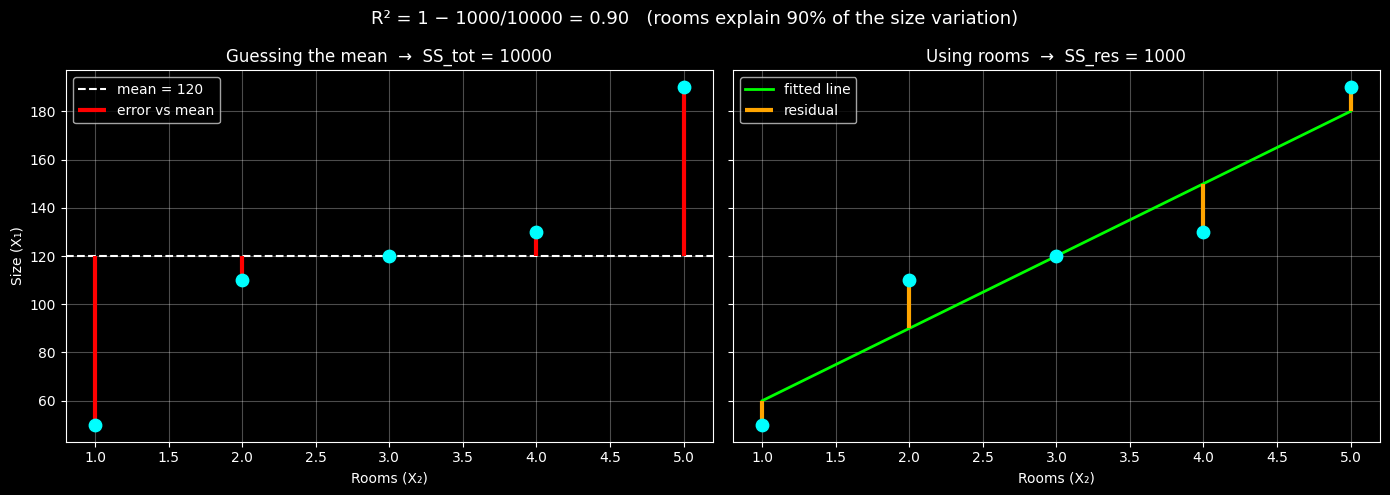

In [30]:
# Toy example: can "rooms" predict "size"?
rooms = np.array([1, 2, 3, 4, 5])
size  = np.array([50, 110, 120, 130, 190])

b, a = np.polyfit(rooms, size, 1)   # slope = 30, intercept = 30
pred = a + b * rooms
mean = size.mean()

ss_tot = ((size - mean) ** 2).sum()
ss_res = ((size - pred) ** 2).sum()
r2 = 1 - ss_res / ss_tot

print(f"Fitted line: size = {a:.0f} + {b:.0f} × rooms\n")
print("House  Rooms  Size  Mean  Err_mean²  Pred  Err_line²")
for h, r, s, p in zip("ABCDE", rooms, size, pred):
    print(f"  {h}     {r}    {s:4d}  {mean:.0f}   {(s-mean)**2:7.0f}   {p:4.0f}   {(s-p)**2:6.0f}")
print(f"\nSS_tot = {ss_tot:.0f}    SS_res = {ss_res:.0f}")
print(f"R² = 1 - {ss_res:.0f}/{ss_tot:.0f} = {r2:.2f}")
print(f"Check with sklearn: {LinearRegression().fit(rooms.reshape(-1, 1), size).score(rooms.reshape(-1, 1), size):.2f}")
print(f"Correlation r = {np.corrcoef(rooms, size)[0, 1]:.4f}  →  r² = {np.corrcoef(rooms, size)[0, 1]**2:.2f}  (same as R² with ONE predictor)")

fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

ax[0].scatter(rooms, size, color='cyan', s=80, zorder=3)
ax[0].axhline(mean, ls='--', color='white', label=f'mean = {mean:.0f}')
ax[0].vlines(rooms, mean, size, colors='red', linewidth=3, label='error vs mean')
ax[0].set_title(f'Guessing the mean  →  SS_tot = {ss_tot:.0f}')

ax[1].scatter(rooms, size, color='cyan', s=80, zorder=3)
ax[1].plot(rooms, pred, color='lime', linewidth=2, label='fitted line')
ax[1].vlines(rooms, pred, size, colors='orange', linewidth=3, label='residual')
ax[1].set_title(f'Using rooms  →  SS_res = {ss_res:.0f}')

for a_ in ax:
    a_.set_xlabel('Rooms (X₂)'); a_.legend(); a_.grid(alpha=0.3)
ax[0].set_ylabel('Size (X₁)')
fig.suptitle(f'R² = 1 − {ss_res:.0f}/{ss_tot:.0f} = {r2:.2f}   (rooms explain {r2:.0%} of the size variation)', fontsize=13)
plt.tight_layout()
plt.show()

### 3.2 The two extremes of R²

- **$R^2 = 1$** (SS_res = 0): every point lies exactly on the line. The feature adds **nothing new**; it is fully redundant.
- **$R^2 = 0$** (SS_res = SS_tot): the best line is flat at the mean. Knowing the other feature doesn't help at all; the two are independent.

The next plot shows both extremes next to our example.

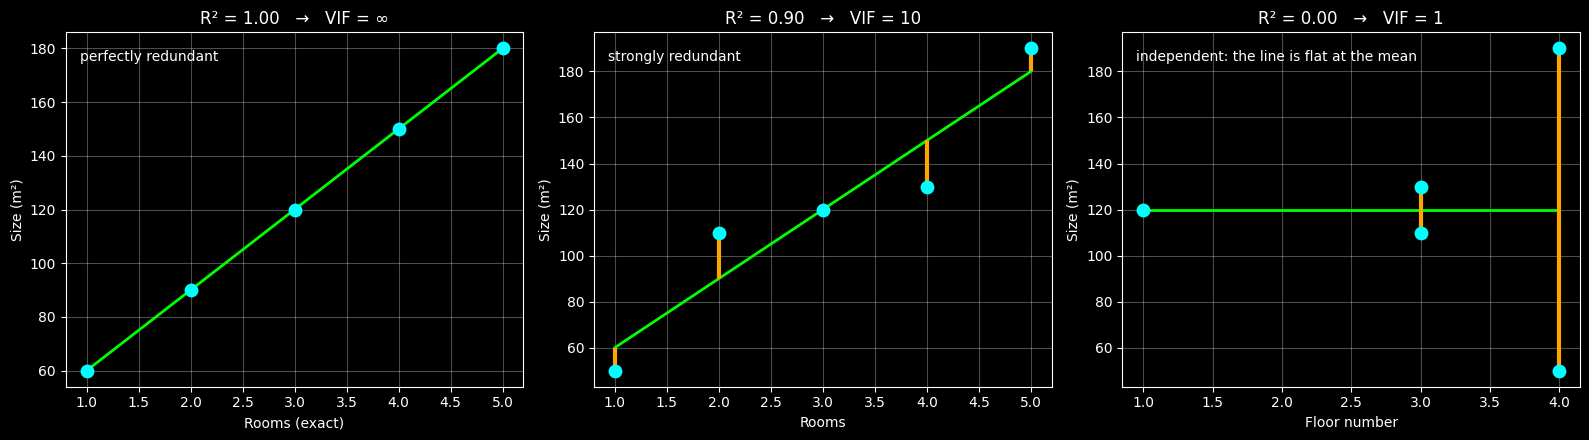

In [31]:
# Three situations side by side: R² = 1, R² = 0.9, R² = 0
size = np.array([50, 110, 120, 130, 190])

cases = [
    ("Rooms (exact)",  np.array([1, 2, 3, 4, 5]), 30 + 30 * np.array([1, 2, 3, 4, 5])),  # size is an exact line of rooms
    ("Rooms",          np.array([1, 2, 3, 4, 5]), size),                                 # our example
    ("Floor number",   np.array([4, 3, 1, 3, 4]), size),                                 # unrelated to size
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (xname, x, y) in zip(axes, cases):
    b, a = np.polyfit(x, y, 1)
    y_hat = a + b * x
    r2 = 1 - ((y - y_hat) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    vif = np.inf if r2 > 0.999 else 1 / (1 - r2)

    xs = np.linspace(x.min(), x.max(), 50)
    ax.scatter(x, y, color='cyan', s=80, zorder=3)
    ax.plot(xs, a + b * xs, color='lime', linewidth=2)
    ax.vlines(x, y_hat, y, colors='orange', linewidth=3)
    ax.set_xlabel(xname); ax.set_ylabel('Size (m²)')
    ax.set_title(f'R² = {r2:.2f}   →   VIF = {vif:.0f}' if np.isfinite(vif) else f'R² = {r2:.2f}   →   VIF = ∞')
    ax.grid(alpha=0.3)

axes[0].text(0.03, 0.95, 'perfectly redundant', transform=axes[0].transAxes, va='top')
axes[1].text(0.03, 0.95, 'strongly redundant', transform=axes[1].transAxes, va='top')
axes[2].text(0.03, 0.95, 'independent: the line is flat at the mean', transform=axes[2].transAxes, va='top')
plt.tight_layout()
plt.show()

Each dot = the coefficients fitted on a new sample of $y = 2A + 3B + \text{noise}$. Red × = true values.

**Same population, new samples:** the stronger the correlation between A and B, the more the fitted coefficients vary from sample to sample. That spread is the variance VIF inflates.

**Today vs. tomorrow:** each new dataset is a random sample, so the fitted coefficients are random too; when A ≈ B the model splits the credit using only their tiny differences, which change with every sample.

**When A and B are weakly correlated:** each feature carries its own unique variation, so tomorrow's noise still moves the coefficients a little (VIF = 1 is the minimum wobble) but is not amplified.

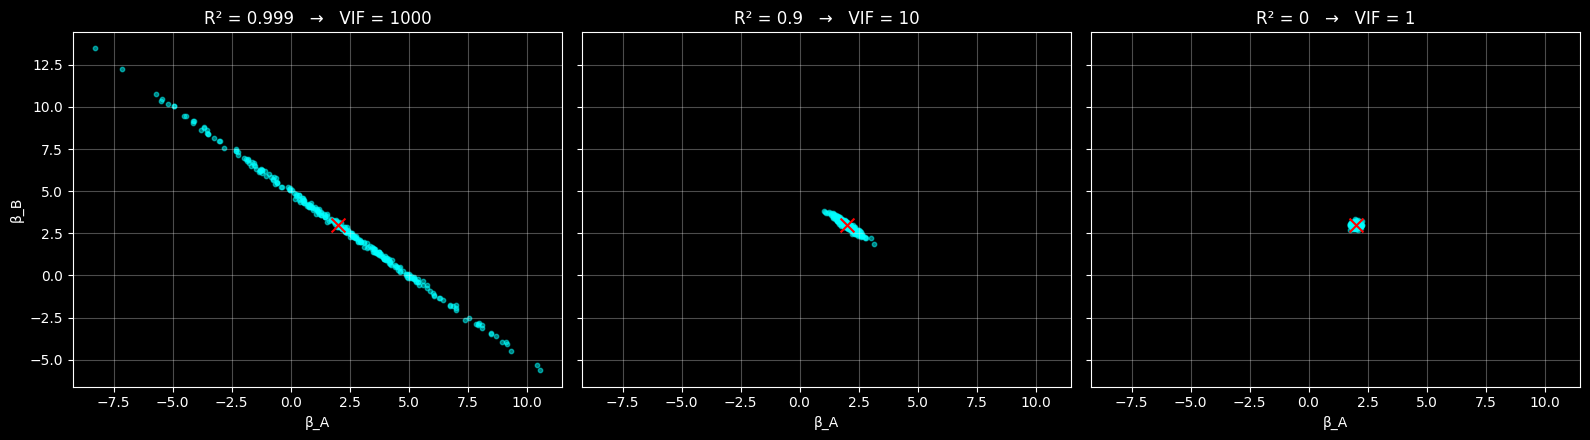

In [32]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True)
for ax, r2 in zip(axes, [0.999, 0.9, 0]):
    betas = []
    for _ in range(300):
        A = rng.standard_normal(100)
        B = np.sqrt(r2) * A + np.sqrt(1 - r2) * rng.standard_normal(100)
        y = 2 * A + 3 * B + rng.standard_normal(100)
        betas.append(LinearRegression().fit(np.column_stack([A, B]), y).coef_)
    betas = np.array(betas)
    ax.scatter(betas[:, 0], betas[:, 1], s=10, alpha=0.5, color='cyan')
    ax.scatter(2, 3, color='red', s=100, marker='x')
    ax.set_title(f'R² = {r2}   →   VIF = {1 / (1 - r2):.0f}')
    ax.set_xlabel('β_A')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('β_B')
plt.tight_layout()
plt.show()

### 3.3 From R² to VIF (Variance Inflation Factor)

**Idea:** for each feature, ask *"how well can the **other** features predict this one?"*

**Step 1: the auxiliary regression.** To get the VIF of $X_1$, we put the real target $y$ aside and fit a regression that uses $X_1$ as the target:

$$X_1 = \beta_0 + \beta_2 X_2 + \beta_3 X_3 + \dots + \varepsilon$$

We repeat this for every feature, so $p$ features need $p$ separate regressions. The real target $y$ is never used.

| VIF for | Target of the auxiliary regression | Predictors |
|---|---|---|
| $X_1$ | $X_1$ | $X_2, X_3, X_4$ |
| $X_2$ | $X_2$ | $X_1, X_3, X_4$ |
| $X_3$ | $X_3$ | $X_1, X_2, X_4$ |

**Step 2: take that regression's $R_i^2$** (exactly as computed in 3.1).

**Step 3: turn it into VIF:**

$$VIF_i = \frac{1}{1 - R_i^2}$$

The denominator $1 - R_i^2$ is called the **tolerance**: the share of $X_i$ that is *unique*, meaning not explained by the other features.

| $R_i^2$ | Tolerance | VIF | Meaning |
|---|---|---|---|
| 0.00 | 1.00 | 1 | Fully independent |
| 0.50 | 0.50 | 2 | Half of $X_i$ is redundant |
| 0.80 | 0.20 | 5 | Moderate |
| 0.90 | 0.10 | 10 | High (our house example!) |
| 0.99 | 0.01 | 100 | Almost a copy of the others |


**Rule of thumb:**

- VIF < 5: Low multicollinearity
- VIF 5-10: Moderate multicollinearity
- VIF > 10: High multicollinearity (problematic!)

**Limitation:** VIF won't be able to tell which feature correlated with which. A high VIF only says that *some combination* of the other features predicts this one. To find the culprits, check the correlation heatmap, or look at the coefficients of that feature's auxiliary regression.

In [33]:
# Compute VIF for each feature
def compute_vif(X):
    """Compute VIF for each feature"""
    vif_data = []
    for i in range(X.shape[1]):
        # Use all other features to predict feature i
        X_i = X[:, i]
        X_others = np.delete(X, i, axis=1)

        # Fit linear regression
        lr = LinearRegression()
        lr.fit(X_others, X_i)

        # Compute R²
        r_squared = lr.score(X_others, X_i)

        # VIF = 1 / (1 - R²)
        vif = 1 / (1 - r_squared) if r_squared < 0.999 else np.inf
        vif_data.append(vif)

    return np.array(vif_data)


X_housing = housing.data
vif_values = compute_vif(X_housing)

print("Feature                VIF")
print("-" * 35)
for name, vif in zip(housing.feature_names, vif_values):
    print(f"{name:15s} {vif:10.2f}")

Feature                VIF
-----------------------------------
MedInc                2.50
HouseAge              1.24
AveRooms              8.34
AveBedrms             6.99
Population            1.14
AveOccup              1.01
Latitude              9.30
Longitude             8.96


### Exercise 3: Compute VIF

**Task:** Compute VIF for the Diabetes dataset features.


In [34]:
# Load diabetes data
diabetes = load_diabetes()
X_diabetes = diabetes.data[:, :5]  # Use first 5 features
feature_names_diabetes = ['Age', 'Sex', 'BMI', 'BP', 'S1']

print(f"Diabetes features: {feature_names_diabetes}")

Diabetes features: ['Age', 'Sex', 'BMI', 'BP', 'S1']


In [36]:
# YOUR TASK: Compute VIF for diabetes features
# YOUR CODE HERE


def compute_vif(X):
    """Compute VIF for each feature"""
    vif_data = []
    for i in range(X.shape[1]):
        # Use all other features to predict feature i
        X_i = X[:, i]
        X_others = np.delete(X, i, axis=1)

        # Fit linear regression
        lr = LinearRegression()
        lr.fit(X_others, X_i)

        # Compute R²
        r_squared = lr.score(X_others, X_i)

        # VIF = 1 / (1 - R²)
        vif = 1 / (1 - r_squared) if r_squared < 0.999 else np.inf
        vif_data.append(vif)

    return np.array(vif_data)



vif_values = compute_vif(X_diabetes)

print("Feature                VIF")
print("-" * 35)
for name, vif in zip(feature_names_diabetes, vif_values):
    print(f"{name:15s} {vif:10.2f}")

Feature                VIF
-----------------------------------
Age                   1.19
Sex                   1.08
BMI                   1.22
BP                    1.36
S1                    1.14


In [37]:
# print("✅ Exercise 3 passed!")

---

# 4. Handling Multicollinearity

Two ways to decide which features to remove:

- **4.1 Pairwise:** remove one feature from every highly correlated pair
- **4.2 Multivariate:** use VIF and the auxiliary regression (catches what pairwise misses)

In [38]:
# Create dataset with SEVERE multicollinearity
np.random.seed(42)
n = 500

# Base feature
x1 = np.random.randn(n)

# Highly correlated features
x2 = x1 + np.random.randn(n) * 0.1  # Almost identical to x1
x3 = 2 * x1 + np.random.randn(n) * 0.1  # Linear combination of x1
x4 = np.random.randn(n)  # Independent feature

# Target depends on x1 and x4
y = 3 * x1 + 2 * x4 + np.random.randn(n) * 0.5

X_multicol = np.column_stack([x1, x2, x3, x4])
feature_names_demo = ['X1', 'X2 (≈X1)', 'X3 (≈2×X1)', 'X4']

# Check correlations
corr_demo = np.corrcoef(X_multicol.T)
print("Correlation Matrix:")
print("               ", "  ".join(f"{name:12s}" for name in feature_names_demo))
for i, name in enumerate(feature_names_demo):
    print(f"{name:8s}", "  ".join(f"{corr_demo[i,j]:12.3f}" for j in range(4)))

Correlation Matrix:
                X1            X2 (≈X1)      X3 (≈2×X1)    X4          
X1              1.000         0.995         0.999         0.064
X2 (≈X1)        0.995         1.000         0.994         0.062
X3 (≈2×X1)        0.999         0.994         1.000         0.063
X4              0.064         0.062         0.063         1.000


### 4.1 Pairwise approach: remove one feature from each highly correlated pair

In [39]:
# Remove features with correlation > 0.9
def remove_correlated_features(X, feature_names, threshold=0.9):
    """Remove features with correlation > threshold"""
    corr = np.corrcoef(X.T)
    to_remove = set()

    for i in range(len(feature_names)):
        for j in range(i+1, len(feature_names)):
            if abs(corr[i, j]) > threshold and j not in to_remove:
                to_remove.add(j)
                print(f"  Removing {feature_names[j]} (corr with {feature_names[i]}: {corr[i,j]:.3f})")

    keep_indices = [i for i in range(len(feature_names)) if i not in to_remove]
    return X[:, keep_indices], [feature_names[i] for i in keep_indices]


X_reduced, names_reduced = remove_correlated_features(X_multicol, feature_names_demo, threshold=0.9)
print(f"\nReduced from {X_multicol.shape[1]} to {X_reduced.shape[1]} features")
print(f"Remaining: {names_reduced}")

  Removing X2 (≈X1) (corr with X1: 0.995)
  Removing X3 (≈2×X1) (corr with X1: 0.999)

Reduced from 4 to 2 features
Remaining: ['X1', 'X4']


### 4.2 Multivariate approach: when pairwise correlation is not enough

In 4.1 every redundant feature was a near-copy of **one** other feature, so pairwise correlation was enough.

But remember from 3.1: $R^2$ can be high even when **no single pair** looks strongly correlated. Here is that case:

- $X_1$, $X_2$, $X_4$ are independent
- $X_3 \approx X_1 + X_2$: it's redundant **given both** $X_1$ and $X_2$, but it looks only moderately similar to each one alone

We follow 4 steps:

1. **Correlation matrix:** does the pairwise check catch it?
2. **VIF:** is there multicollinearity?
3. **Auxiliary regression coefficients:** *which* features are involved?
4. **Remove one feature and recompute VIF:** did it work?

In [40]:
# Step 1: create a dataset with MULTIVARIATE multicollinearity
np.random.seed(42)
n = 500

z1 = np.random.randn(n)
z2 = np.random.randn(n)                    # independent of z1
z4 = np.random.randn(n)                    # independent feature
z3 = z1 + z2 + np.random.randn(n) * 0.1    # combination of z1 AND z2

X_mv = np.column_stack([z1, z2, z3, z4])
names_mv = ['X1', 'X2', 'X3 (≈X1+X2)', 'X4']

# Check correlations: every pair is only ~0.7
corr_mv = np.corrcoef(X_mv.T)
print("Correlation Matrix:")
print("            ", "  ".join(f"{name:12s}" for name in names_mv))
for i, name in enumerate(names_mv):
    print(f"{name:12s}", "  ".join(f"{corr_mv[i,j]:12.3f}" for j in range(4)))

# Try the pairwise method from 4.1
print("\nPairwise removal with threshold 0.9:")
X_tmp, names_tmp = remove_correlated_features(X_mv, names_mv, threshold=0.9)
print(f"Remaining: {names_tmp}  →  nothing removed!")

Correlation Matrix:
             X1            X2            X3 (≈X1+X2)   X4          
X1                  1.000        -0.076         0.682        -0.058
X2                 -0.076         1.000         0.674         0.076
X3 (≈X1+X2)         0.682         0.674         1.000         0.012
X4                 -0.058         0.076         0.012         1.000

Pairwise removal with threshold 0.9:
Remaining: ['X1', 'X2', 'X3 (≈X1+X2)', 'X4']  →  nothing removed!


The pairwise check sees nothing (r ≈ 0.7 < 0.9), yet $X_3$ is almost fully explained by $X_1$ and $X_2$ **together**.

**Step 2:** VIF looks at each feature against **all** the others at once, so it should catch this.

In [41]:
# Step 2: VIF
vif_mv = compute_vif(X_mv)

print("Feature           VIF")
print("-" * 30)
for name, vif in zip(names_mv, vif_mv):
    flag = "  ← high" if vif > 10 else ""
    print(f"{name:12s} {vif:10.2f}{flag}")

Feature           VIF
------------------------------
X1               102.15  ← high
X2                99.94  ← high
X3 (≈X1+X2)      185.92  ← high
X4                 1.01


VIF flags **three** features: $X_1$, $X_2$ and $X_3$. That makes sense: if $X_3 \approx X_1 + X_2$, then also $X_1 \approx X_3 - X_2$ and $X_2 \approx X_3 - X_1$. Each of them is predictable from the other two.

But (the limitation from 3.3) VIF alone doesn't tell us **who is related to whom**.

**Step 3:** open up the auxiliary regression of the highest-VIF feature and look at its **coefficients**:

- A large coefficient means that feature is part of the redundancy
- A coefficient near 0 means that feature is not involved

**Standardize first!** Raw coefficients depend on units (meters vs. km would change a coefficient 1000×). After standardizing, all features are on the same scale and the coefficients can be compared.

In [42]:
# Step 3: regression of the highest-VIF feature (on standardized features)
X_mv_std = StandardScaler().fit_transform(X_mv)

target_idx = np.argmax(vif_mv)
X_i = X_mv_std[:, target_idx]
X_others = np.delete(X_mv_std, target_idx, axis=1)
others_names = [nm for k, nm in enumerate(names_mv) if k != target_idx]

aux = LinearRegression().fit(X_others, X_i)

print(f"Auxiliary regression: {names_mv[target_idx]} predicted from the others (standardized)")
print(f"R² = {aux.score(X_others, X_i):.4f}\n")
print("Predictor      Std. coefficient")
print("-" * 32)
for nm, c in zip(others_names, aux.coef_):
    print(f"{nm:12s} {c:10.3f}")

Auxiliary regression: X3 (≈X1+X2) predicted from the others (standardized)
R² = 0.9946

Predictor      Std. coefficient
--------------------------------
X1                0.738
X2                0.729
X4               -0.001


The coefficients reveal the group: $X_3$ is built from $X_1$ and $X_2$ (≈0.7 each), and $X_4$ is not involved (≈0).

**Step 4: which one do we remove?** Removing **any one** of $X_1, X_2, X_3$ breaks the dependency. The coefficients show *who* is involved, but choosing *which* to drop is a separate decision:

- **Domain knowledge:** drop the "derived" feature (e.g. a total that is the sum of its parts)
- **Relation to the target:** drop the one least correlated with $y$
- **Effect on VIF:** drop the one whose removal lowers the remaining VIFs the most

Here $X_3$ is the derived one, so we drop it and **recompute VIF** to check.

In [43]:
# Step 4: remove X3 and recompute VIF
drop_idx = names_mv.index('X3 (≈X1+X2)')
X_mv_reduced = np.delete(X_mv, drop_idx, axis=1)
names_mv_reduced = [nm for k, nm in enumerate(names_mv) if k != drop_idx]

vif_after = compute_vif(X_mv_reduced)

print("Feature       VIF before   VIF after")
print("-" * 40)
for nm, vb in zip(names_mv, vif_mv):
    if nm in names_mv_reduced:
        print(f"{nm:12s} {vb:10.2f}   {vif_after[names_mv_reduced.index(nm)]:9.2f}")
    else:
        print(f"{nm:12s} {vb:10.2f}     removed")

Feature       VIF before   VIF after
----------------------------------------
X1               102.15        1.01
X2                99.94        1.01
X3 (≈X1+X2)      185.92     removed
X4                 1.01        1.01


Removing just **one** feature brought all VIFs back to ≈1.

### 4.3 General case: iterative VIF elimination

With many features there can be several overlapping groups. A simple, general procedure:

1. Compute VIF for all features
2. If the highest VIF > threshold, remove that feature
3. **Recompute** VIF and repeat until all VIFs ≤ threshold

Why recompute after each removal? Removing one feature changes everyone else's VIF (as we just saw: $X_1$ and $X_2$ dropped from ≈100 to ≈1). Removing all high-VIF features at once would throw away $X_1$, $X_2$ **and** $X_3$, when only one had to go.

In [44]:
# Iteratively remove the feature with the highest VIF
def remove_high_vif_features(X, feature_names, threshold=10):
    """Remove the highest-VIF feature one at a time until all VIFs <= threshold"""
    X, names = X.copy(), list(feature_names)
    while True:
        vifs = compute_vif(X)
        worst = np.argmax(vifs)
        if vifs[worst] <= threshold:
            break
        print(f"  Removing {names[worst]} (VIF = {vifs[worst]:.1f})")
        X = np.delete(X, worst, axis=1)
        names.pop(worst)
    return X, names


print("Multivariate example (4.2):")
_, kept = remove_high_vif_features(X_mv, names_mv)
print(f"Remaining: {kept}\n")

print("Pairwise example (4.1):")
_, kept = remove_high_vif_features(X_multicol, feature_names_demo)
print(f"Remaining: {kept}")

Multivariate example (4.2):
  Removing X3 (≈X1+X2) (VIF = 185.9)
Remaining: ['X1', 'X2', 'X4']

Pairwise example (4.1):
  Removing X1 (VIF = 451.9)
  Removing X3 (≈2×X1) (VIF = 84.6)
Remaining: ['X2 (≈X1)', 'X4']


**Notice:** in the 4.1 example, VIF removed $X_1$, even though $y$ was generated from $X_1$! That's fine for prediction, because the kept $X_2 \approx X_1$ carries the same information. But it reminds us that **VIF never looks at the target**. It's an automatic rule; when you know which feature is the "real" one, use that knowledge (Step 4 above).

**Takeaway:**

| Tool | Answers |
|---|---|
| Correlation matrix | Which **pairs** are similar? (misses combinations) |
| VIF | **Is** this feature redundant given **all** the others? |
| Recompute VIF after removal | Did the removal **fix** it? |

---

## Summary

✅ **Data Visualization:**

- Histograms reveal distributions
- Box plots detect outliers
- Scatter matrices show relationships

✅ **Correlation Analysis:**

- Identify feature-target relationships
- Find redundant features

✅ **Multicollinearity Detection:**

- Use correlation matrix (pairs only)
- Compute VIF (each feature vs. all the others together)
- Standardized auxiliary-regression coefficients show *which* features are involved

✅ **Handling Multicollinearity:**

- Pairwise: remove one feature from each highly correlated pair
- Multivariate: remove one feature per redundant group, then recompute VIF
- Iterative VIF elimination for the general case